In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import os

In [2]:
dir = r'C:\Users\agbob\OSUCLAB\ADD\FOSSE\osuc_digital_twin\data'
file_name = 'open-meteo-47.84N1.94E111m.csv'

file_path = os.path.join(dir, file_name)
data = pd.read_csv(file_path)
data.head()

,time,temperature_2m (°C),wind_speed_10m (km/h),soil_temperature_0_to_7cm (°C),soil_temperature_7_to_28cm (°C),soil_temperature_28_to_100cm (°C),soil_temperature_100_to_255cm (°C),wind_direction_10m (°),relative_humidity_2m (%),precipitation (mm)
0,2024-01-01T00:00,6.4,23.5,7.6,8.9,9.9,12.4,230,86,0.0
1,2024-01-01T01:00,6.4,21.9,7.8,8.9,9.9,12.4,224,84,0.0
2,2024-01-01T02:00,6.3,21.9,7.6,8.8,9.9,12.4,224,83,0.0
3,2024-01-01T03:00,6.2,22.1,7.3,8.7,9.9,12.4,224,86,0.0
4,2024-01-01T04:00,5.8,21.1,7.2,8.6,9.9,12.4,227,89,0.0


In [3]:
data['time'] = pd.to_datetime(data['time'])
data.set_index('time', inplace=True)

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

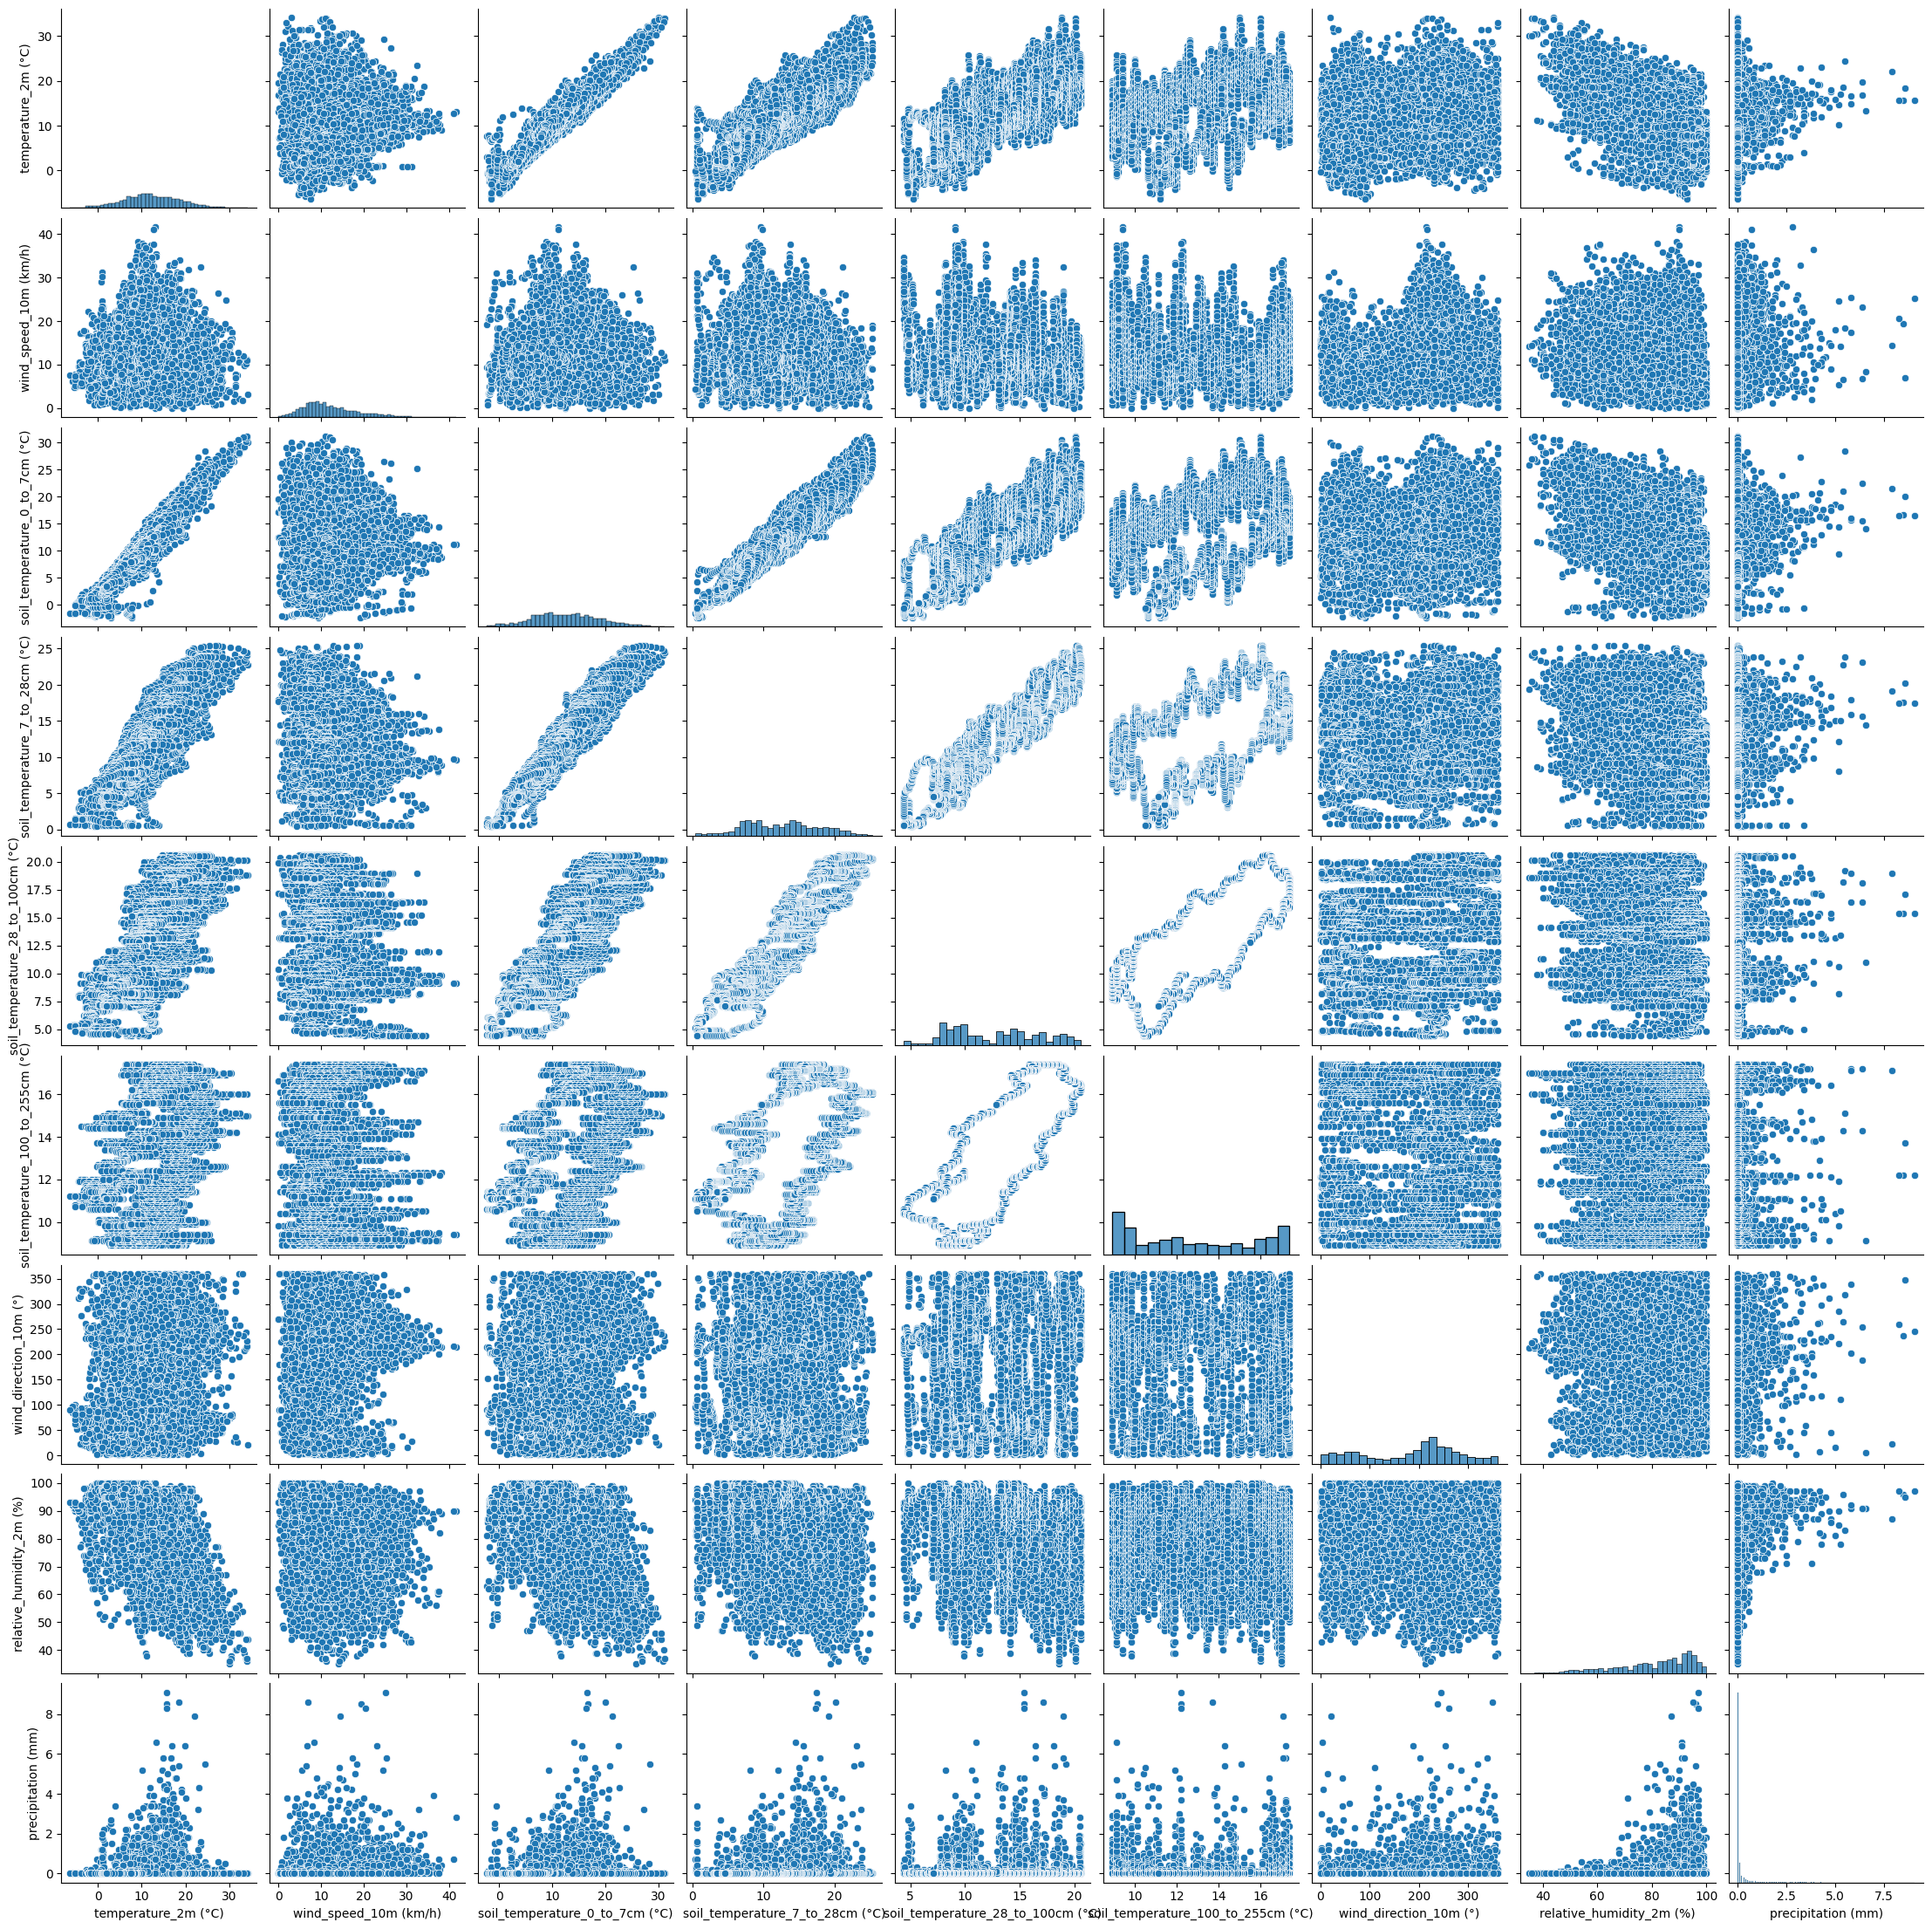

In [5]:
sns.pairplot(data)
plt.show()

In [6]:
data.columns.unique()

Index(['temperature_2m (°C)', 'wind_speed_10m (km/h)',
       'soil_temperature_0_to_7cm (°C)', 'soil_temperature_7_to_28cm (°C)',
       'soil_temperature_28_to_100cm (°C)',
       'soil_temperature_100_to_255cm (°C)', 'wind_direction_10m (°)',
       'relative_humidity_2m (%)', 'precipitation (mm)'],
      dtype='object')

Text(0.5, 0, 'Time')

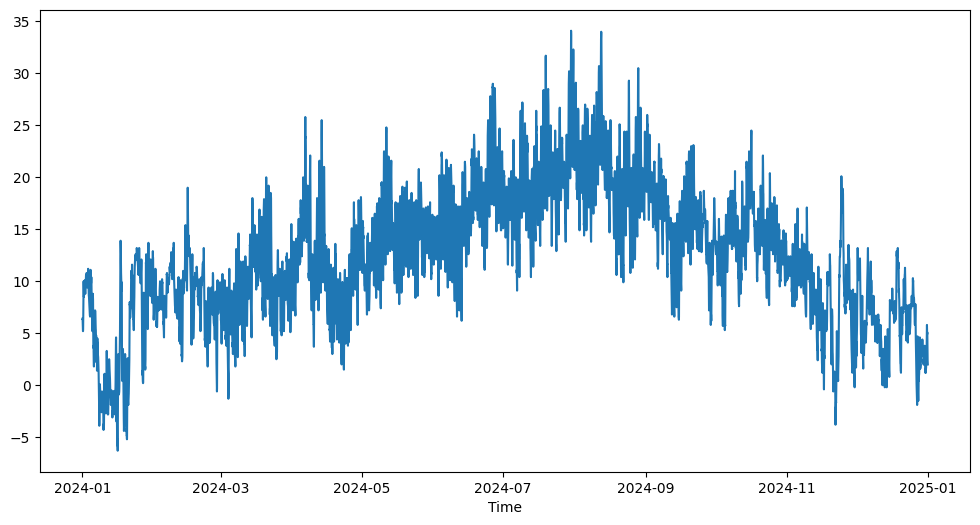

In [7]:
# plot temperature over time
plt.figure(figsize=(12, 6))
plt.plot(data.index, data['temperature_2m (°C)'], label='Temperature at 2m')
plt.xlabel('Time')

Text(0.5, 0, 'Time')

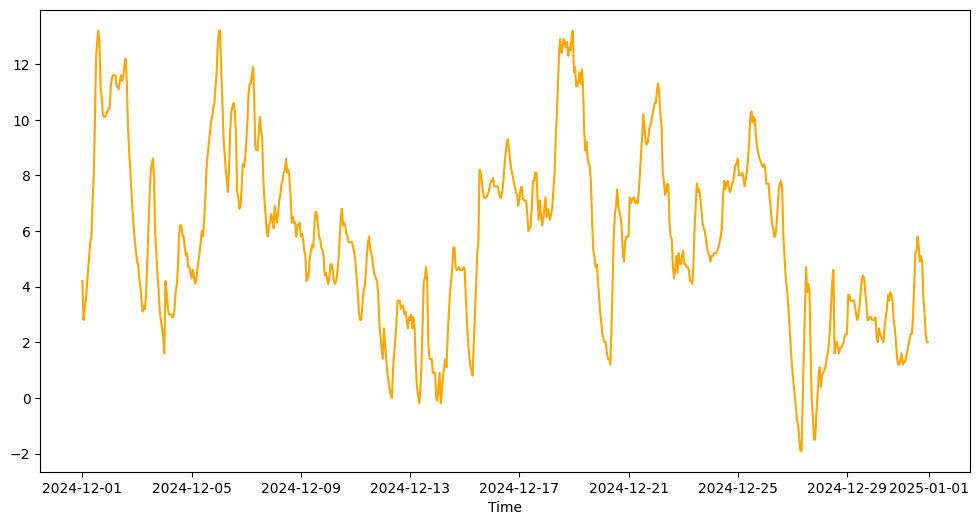

In [8]:
# plot temperature over nov - dec 2024

plt.figure(figsize=(12, 6))
nov_dec_data = data['2024-12-01':'2024-12-31']
plt.plot(nov_dec_data.index, nov_dec_data['temperature_2m (°C)'], label='Temperature at 2m', color='orange')
plt.xlabel('Time')

In [9]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
import itertools
warnings.filterwarnings("ignore")

In [10]:
target = 'soil_temperature_100_to_255cm (°C)'
features = [
    'soil_temperature_0_to_7cm (°C)', 
    'soil_temperature_7_to_28cm (°C)',
    'soil_temperature_28_to_100cm (°C)'
]

X = data[features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

model = SARIMAX(y_train, exog=X_train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
model_fit = model.fit(disp=False)
y_pred = model_fit.predict(start=len(y_train), end=len(y_train)+len(y_test)-1, exog=X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [11]:
print( f'Mean Squared Error: {mse}')
print( f'R^2 Score: {r2}')

Mean Squared Error: 5.691821803749028
R^2 Score: -1.0353634636654485


In [12]:
model_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                       SARIMAX Results                                        
==============================================================================================
Dep. Variable:     soil_temperature_100_to_255cm (°C)   No. Observations:                 7027
Model:                 SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood               19900.613
Date:                                Tue, 27 Jan 2026   AIC                         -39785.226
Time:                                        16:29:58   BIC                         -39730.380
Sample:                                    01-01-2024   HQIC                        -39766.329
                                         - 10-19-2024                                         
Covariance Type:                                  opg                                         
=====================================================================================================
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
soil_temperature_0_to_7cm (°C)       -0.0006      0.000     -2.061      0.039      -0.001   -3.02e-05
soil_temperature_7_to_28cm (°C)    1.332e-05      0.001      0.013      0.990      -0.002       0.002
soil_temperature_28_to_100cm (°C)     0.0016      0.009      0.175      0.861      -0.016       0.019
ar.L1                                 0.0713      0.169      0.422      0.673      -0.260       0.403
ma.L1                                -0.1408      0.174     -0.810      0.418      -0.482       0.200
ar.S.L12                             -0.0070      0.013     -0.534      0.594      -0.033       0.019
ma.S.L12                             -0.9800      0.003   -325.944      0.000      -0.986      -0.974
sigma2                                0.0002   8.38e-07    238.357      0.000       0.000       0.000
===================================================================================
Ljung-Box (L1) (Q):                   0.17   Jarque-Bera (JB):            529692.85
Prob(Q):                              0.68   Prob(JB):                         0.00
Heteroskedasticity (H):               1.11   Skew:                             1.99
Prob(H) (two-sided):                  0.01   Kurtosis:                        45.39
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

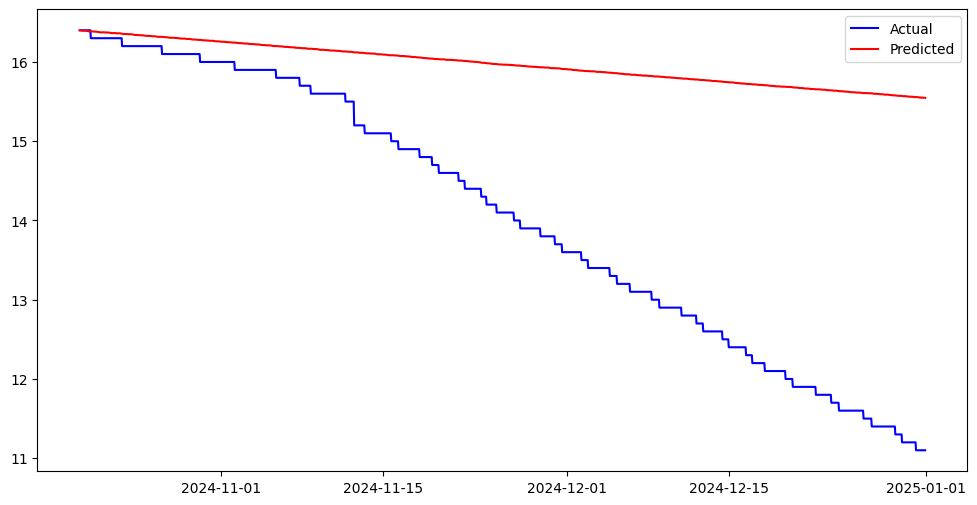

In [13]:
# plot actual vs predicted
plt.figure(figsize=(12, 6))
plt.plot(y_test.index, y_test, label='Actual', color='blue')
plt.plot(y_test.index, y_pred, label='Predicted', color='red')
plt.legend()
plt.show()

In [ ]:
p = d = q = range(1, 4)
pdq = list(itertools.product(p, d, q))
seasonal_pdq = [(x[0], x[1], x[2], 24) for x in pdq]

best_aic = np.inf
best_param = None

for param in pdq:
    for param_seasonal in seasonal_pdq:
        try:
            mod = SARIMAX(
                y_train,
                # exog=X_train,
                order=param,
                seasonal_order=param_seasonal,
                enforce_stationarity=False,
                enforce_invertibility=False,
            )

            results = mod.fit()

            if results.aic < best_aic:
                best_aic = results.aic
                best_param = (param, param_seasonal)

            print(
                f"SARIMAX{param}x{param_seasonal} - AIC:{results.aic}"
            )
        except:
            continue

SARIMAX(1, 1, 1)x(1, 1, 1, 24) - AIC:-39504.77022685677
SARIMAX(1, 1, 1)x(1, 1, 2, 24) - AIC:-39358.84906066301


In [ ]:
print(f"Best SARIMAX{best_param[0]}x{best_param[1]}24 - AIC:{best_aic}")

Best SARIMAX(1, 0, 1)x(0, 0, 0, 12)24 - AIC:-39854.4261351533
